# A6 - Dự đoán giá đóng cửa cổ phiếu Amazon bằng RNN (Keras)

**Dataset:** `AMZN.csv`  
**Framework:** TensorFlow / Keras  
**Mô hình chính:** `SimpleRNN`  
**Bài toán:** dùng **30 phiên giao dịch trước** để dự đoán giá `Close` của **phiên tiếp theo**.

Notebook này được tổ chức theo hướng vừa đúng bài RNN, vừa dễ demo:

1. Load Data
2. Data Understanding
3. Cleaning
4. Visualization / EDA
5. Chọn giai đoạn dùng để modeling
6. Train / Validation / Test Split theo thời gian
7. Scaling - chỉ fit trên Train
8. Create Sequences
9. Build RNN
10. Compile
11. Train
12. Plot Training / Validation Loss
13. Predict
14. Inverse Transform
15. Evaluate + Naive Baseline
16. Actual vs Predicted
17. Hyperparameter Tuning (tùy chọn)
18. Kết luận

> **Nguyên tắc quan trọng:** Dữ liệu chứng khoán là time series nên không shuffle thứ tự thời gian khi chia Train/Validation/Test.

**Bản nộp độc lập:** toàn bộ hàm xử lý dữ liệu, định nghĩa mô hình, huấn luyện
và kiểm tra tải lại đều nằm trong notebook. Không cần các file `.py` của dự án.
Đặt CSV tương ứng cạnh notebook, chọn kernel đã cài thư viện và Restart & Run All.
Chọn checkpoint/cấu hình bằng Validation; Test chỉ dùng để báo cáo cuối cùng.

## 0. Import thư viện

In [1]:
# Nếu cần: %pip install numpy pandas matplotlib scikit-learn tensorflow

from pathlib import Path
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Set before importing a framework; helps deterministic CUDA execution.
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
SEED = int(os.environ.get("RNN_SEED", "42"))
np.random.seed(SEED)
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, SimpleRNN, Dense, Embedding
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
print("TensorFlow:", tf.__version__, "| Pandas:", pd.__version__, "| Seed:", SEED)

TensorFlow: 2.21.0 | Pandas: 2.3.2 | Seed: 42


## 1. Load Data

In [2]:
# Hỗ trợ CSV cạnh notebook hoặc cấu trúc data/ + notebooks/.
candidates = [Path.cwd() / "AMZN.csv",
              Path.cwd() / "data" / "AMZN.csv",
              Path.cwd().parent / "data" / "AMZN.csv"]
DATA_PATH = next((p.resolve() for p in candidates if p.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Đặt AMZN.csv cạnh notebook hoặc trong thư mục data/.")
PROJECT_ROOT = DATA_PATH.parent.parent if DATA_PATH.parent.name == "data" else DATA_PATH.parent
RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
df_raw = pd.read_csv(DATA_PATH)
required_columns = ['Date', 'Open', 'High', 'Low', 'Close', 'Volume']
missing = set(required_columns) - set(df_raw.columns)
if missing:
    raise ValueError(f"Missing required columns: {sorted(missing)}")
print("Data:", DATA_PATH)
print("Results:", RESULTS_DIR)
print("Shape:", df_raw.shape)
display(df_raw.head())

Data: D:\A06\data\AMZN.csv
Results: D:\A06\results
Shape: (6684, 7)


,Date,Open,High,Low,Close,Adj Close,Volume
0,1997-05-15,0.121875,0.125000,0.096354,0.097917,0.097917,1443120000
1,1997-05-16,0.098438,0.098958,0.085417,0.086458,0.086458,294000000
2,1997-05-19,0.088021,0.088542,0.081250,0.085417,0.085417,122136000
3,1997-05-20,0.086458,0.087500,0.081771,0.081771,0.081771,109344000
4,1997-05-21,0.081771,0.082292,0.068750,0.071354,0.071354,377064000


## 2. Data Understanding

In [3]:
print("5 dòng đầu:")
display(df_raw.head())

print("\n5 dòng cuối:")
display(df_raw.tail())

print("\nShape:", df_raw.shape)

print("\nThông tin dữ liệu:")
df_raw.info()

5 dòng đầu:


,Date,Open,High,Low,Close,Adj Close,Volume
0,1997-05-15,0.121875,0.125000,0.096354,0.097917,0.097917,1443120000
1,1997-05-16,0.098438,0.098958,0.085417,0.086458,0.086458,294000000
2,1997-05-19,0.088021,0.088542,0.081250,0.085417,0.085417,122136000
3,1997-05-20,0.086458,0.087500,0.081771,0.081771,0.081771,109344000
4,1997-05-21,0.081771,0.082292,0.068750,0.071354,0.071354,377064000



5 dòng cuối:


,Date,Open,High,Low,Close,Adj Close,Volume
6679,2023-11-29,147.850006,148.539993,145.970001,146.320007,146.320007,40610900
6680,2023-11-30,144.759995,146.929993,144.330002,146.089996,146.089996,65814000
6681,2023-12-01,146.000000,147.250000,145.550003,147.029999,147.029999,39924600
6682,2023-12-04,145.250000,145.350006,142.809998,144.839996,144.839996,48294200
6683,2023-12-05,143.550003,148.570007,143.130005,146.880005,146.880005,46754800



Shape: (6684, 7)

Thông tin dữ liệu:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6684 entries, 0 to 6683
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       6684 non-null   object 
 1   Open       6684 non-null   float64
 2   High       6684 non-null   float64
 3   Low        6684 non-null   float64
 4   Close      6684 non-null   float64
 5   Adj Close  6684 non-null   float64
 6   Volume     6684 non-null   int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 365.7+ KB


In [4]:
print("Thống kê mô tả:")
display(df_raw.describe(include="all"))

Thống kê mô tả:


,Date,Open,High,Low,Close,Adj Close,Volume
count,6684,6684.000000,6684.000000,6684.000000,6684.000000,6684.000000,6.684000e+03
unique,6684,NaN,NaN,NaN,NaN,NaN,NaN
top,1997-05-15,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,34.029317,34.439204,33.584667,34.020316,34.020316,1.403786e+08
std,NaN,49.856923,50.442953,49.213548,49.829566,49.829566,1.390747e+08
min,NaN,0.070313,0.072396,0.065625,0.069792,0.069792,9.744000e+06
25%,NaN,2.036875,2.074750,1.994625,2.042500,2.042500,6.716950e+07
50%,NaN,7.123500,7.178000,6.986750,7.104750,7.104750,1.039790e+08
75%,NaN,45.203874,45.475624,44.870125,45.135750,45.135750,1.587810e+08


### Ý nghĩa các cột

- `Date`: ngày giao dịch.
- `Open`: giá mở cửa.
- `High`: giá cao nhất trong phiên.
- `Low`: giá thấp nhất trong phiên.
- `Close`: giá đóng cửa.
- `Adj Close`: giá đóng cửa đã điều chỉnh.
- `Volume`: khối lượng giao dịch.

Trong model RNN cơ bản này, ta dùng **`Close`** làm biến cần dự đoán để bài toán dễ hiểu và dễ demo.

## 3. Cleaning

In [5]:
df = df_raw.copy()

print("Missing values trước xử lý:")
display(df.isna().sum())

print("\nSố dòng trùng hoàn toàn:", df.duplicated().sum())

# Chuyển Date sang datetime
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Các cột số
numeric_cols = ["Open", "High", "Low", "Close", "Adj Close", "Volume"]

for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Loại các dòng không có Date hoặc Close
df = df.dropna(subset=["Date", "Close"]).copy()

# Nếu có nhiều bản ghi cùng ngày thì giữ bản ghi cuối
duplicate_dates = df["Date"].duplicated().sum()
print("Số Date bị trùng:", duplicate_dates)

df = (
    df.sort_values("Date")
      .drop_duplicates(subset=["Date"], keep="last")
      .reset_index(drop=True)
)

print("\nSau cleaning:")
print("Shape:", df.shape)
print("Date tăng dần:", df["Date"].is_monotonic_increasing)
print("Missing values:")
display(df.isna().sum())

print("Khoảng thời gian:",
      df["Date"].min().date(), "->", df["Date"].max().date())

Missing values trước xử lý:


Date         0
Open         0
High         0
Low          0
Close        0
Adj Close    0
Volume       0
dtype: int64


Số dòng trùng hoàn toàn: 0
Số Date bị trùng: 0

Sau cleaning:
Shape: (6684, 7)
Date tăng dần: True
Missing values:


Date         0
Open         0
High         0
Low          0
Close        0
Adj Close    0
Volume       0
dtype: int64

Khoảng thời gian: 1997-05-15 -> 2023-12-05


### Outlier trong chứng khoán

Không tự động xóa các điểm giá cao/thấp bằng IQR, vì biến động mạnh và các giai đoạn tăng/giảm giá có thể là **dữ liệu thật**, không phải lỗi.

Thay vì xóa outlier, ta quan sát chuỗi theo thời gian và giữ nguyên dữ liệu hợp lệ.

## 4. Visualization / EDA

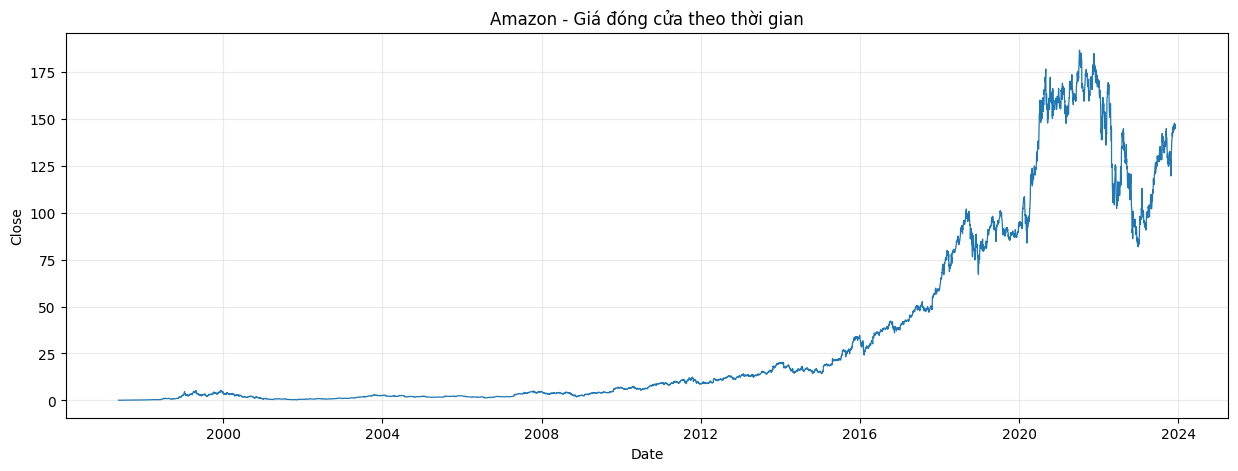

In [6]:
# 4.1. Giá Close toàn bộ lịch sử

plt.figure(figsize=(15, 5))
plt.plot(df["Date"], df["Close"], linewidth=0.9)
plt.title("Amazon - Giá đóng cửa theo thời gian")
plt.xlabel("Date")
plt.ylabel("Close")
plt.grid(alpha=0.25)
plt.show()

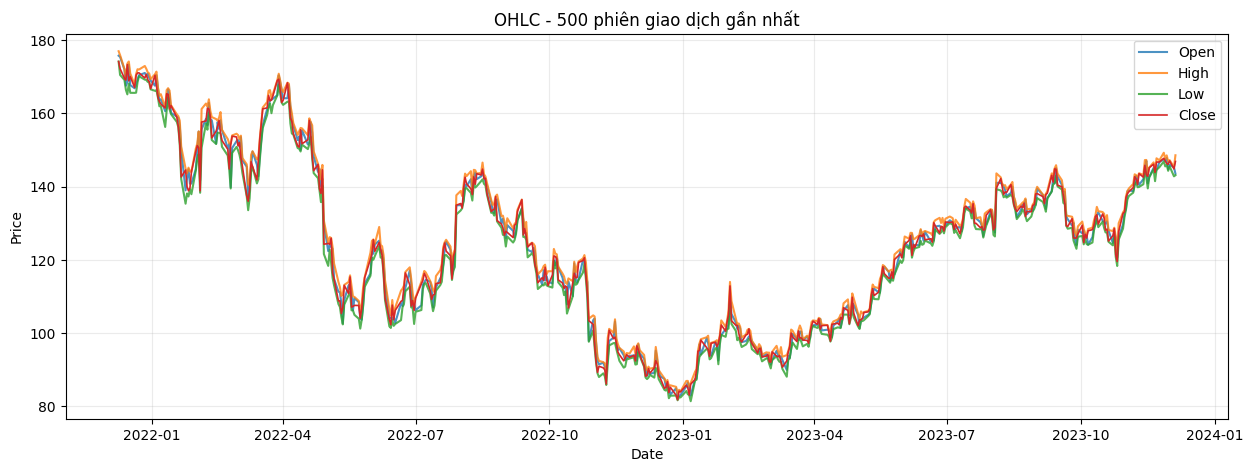

In [7]:
# 4.2. Open / High / Low / Close ở 500 phiên gần nhất

recent_500 = df.tail(500)

plt.figure(figsize=(15, 5))
plt.plot(recent_500["Date"], recent_500["Open"], label="Open", alpha=0.8)
plt.plot(recent_500["Date"], recent_500["High"], label="High", alpha=0.8)
plt.plot(recent_500["Date"], recent_500["Low"], label="Low", alpha=0.8)
plt.plot(recent_500["Date"], recent_500["Close"], label="Close", linewidth=1.2)

plt.title("OHLC - 500 phiên giao dịch gần nhất")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

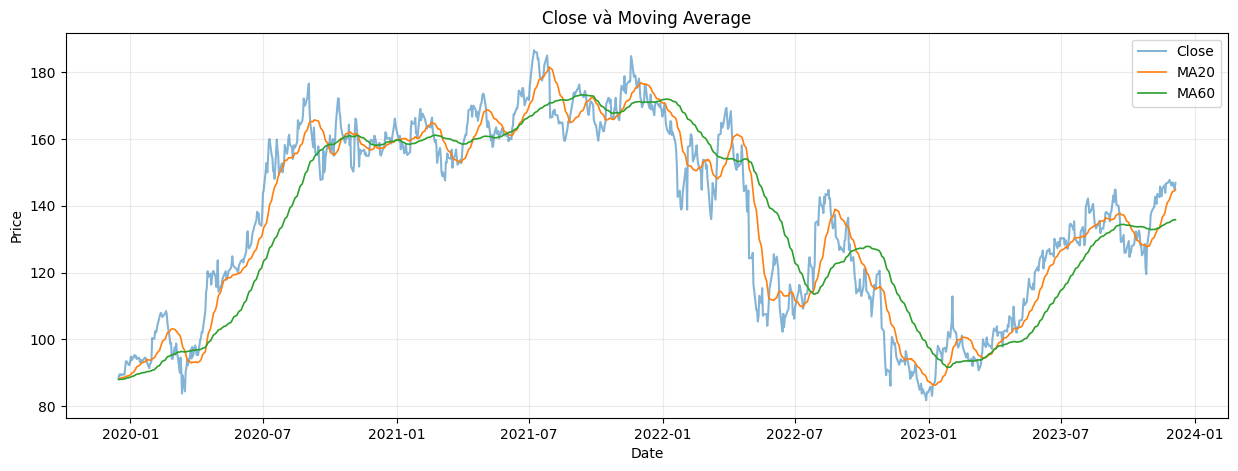

In [8]:
# 4.3. Moving Average để quan sát xu hướng

eda = df[["Date", "Close"]].copy()
eda["MA20"] = eda["Close"].rolling(20).mean()
eda["MA60"] = eda["Close"].rolling(60).mean()

recent = eda.tail(1000)

plt.figure(figsize=(15, 5))
plt.plot(recent["Date"], recent["Close"], label="Close", alpha=0.55)
plt.plot(recent["Date"], recent["MA20"], label="MA20", linewidth=1.2)
plt.plot(recent["Date"], recent["MA60"], label="MA60", linewidth=1.2)

plt.title("Close và Moving Average")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

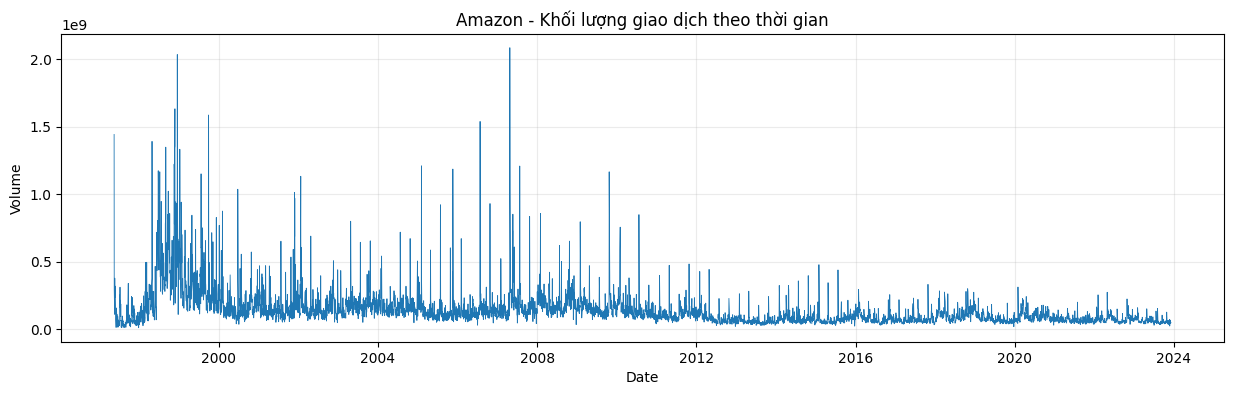

In [9]:
# 4.4. Volume

plt.figure(figsize=(15, 4))
plt.plot(df["Date"], df["Volume"], linewidth=0.6)
plt.title("Amazon - Khối lượng giao dịch theo thời gian")
plt.xlabel("Date")
plt.ylabel("Volume")
plt.grid(alpha=0.25)
plt.show()

Thống kê Daily Return (%):


count    6683.000000
mean        0.172280
std         3.577751
min       -24.766064
25%        -1.319283
50%         0.044425
75%         1.482147
max        34.471366
Name: Close, dtype: float64

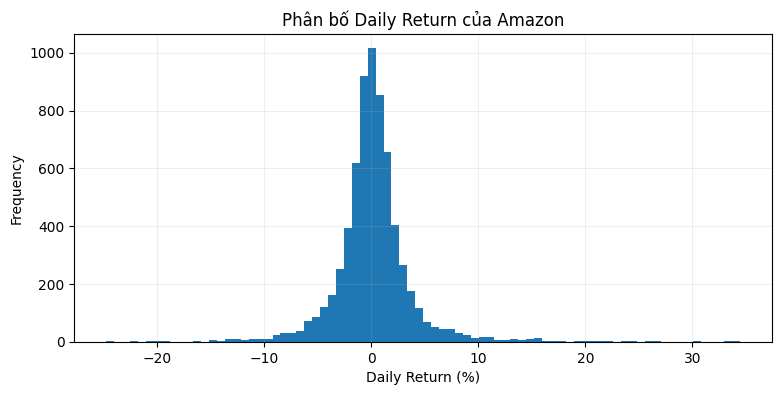

In [10]:
# 4.5. Daily Return - phần trăm thay đổi Close theo ngày

daily_return = df["Close"].pct_change().dropna() * 100

print("Thống kê Daily Return (%):")
display(daily_return.describe())

plt.figure(figsize=(9, 4))
plt.hist(daily_return, bins=80)
plt.title("Phân bố Daily Return của Amazon")
plt.xlabel("Daily Return (%)")
plt.ylabel("Frequency")
plt.grid(alpha=0.2)
plt.show()

## 5. Chọn giai đoạn dùng để Modeling

Dữ liệu Amazon kéo dài nhiều năm và mức giá ở giai đoạn rất xa trước đây thấp hơn rất nhiều so với giai đoạn gần đây.

Để mô hình `SimpleRNN` học trên một giai đoạn có **quy mô giá tương đối đồng nhất**, đồng thời vẫn giữ đủ số lượng quan sát, ta dùng dữ liệu từ **01/01/2015 trở đi** cho phần modeling.

Phần EDA ở trên vẫn phân tích **toàn bộ dataset**.

In [11]:
MODEL_START_DATE = "2015-01-01"

model_df = (
    df[df["Date"] >= MODEL_START_DATE][["Date", "Close"]]
    .copy()
    .reset_index(drop=True)
)

print("Modeling period:")
print(model_df["Date"].min().date(), "->", model_df["Date"].max().date())
print("Số phiên:", len(model_df))

display(model_df.head())

Modeling period:
2015-01-02 -> 2023-12-05
Số phiên: 2247


,Date,Close
0,2015-01-02,15.4260
1,2015-01-05,15.1095
2,2015-01-06,14.7645
3,2015-01-07,14.9210
4,2015-01-08,15.0230


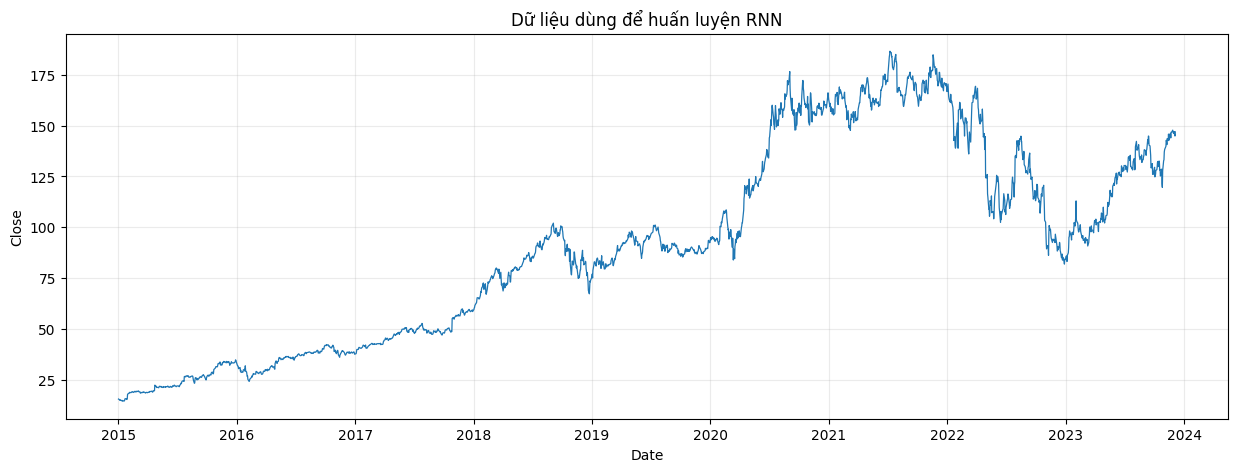

In [12]:
plt.figure(figsize=(15, 5))
plt.plot(model_df["Date"], model_df["Close"], linewidth=0.9)
plt.title("Dữ liệu dùng để huấn luyện RNN")
plt.xlabel("Date")
plt.ylabel("Close")
plt.grid(alpha=0.25)
plt.show()

## 6. Train / Validation / Test Split theo thời gian

In [13]:
# 70% Train - 15% Validation - 15% Test
# KHÔNG chia ngẫu nhiên.

n = len(model_df)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_df = model_df.iloc[:train_end].copy()
val_df = model_df.iloc[train_end:val_end].copy()
test_df = model_df.iloc[val_end:].copy()

print("Tổng số dòng:", n)
print()
print("Train:")
print(train_df.shape,
      train_df["Date"].min().date(), "->", train_df["Date"].max().date())

print("\nValidation:")
print(val_df.shape,
      val_df["Date"].min().date(), "->", val_df["Date"].max().date())

print("\nTest:")
print(test_df.shape,
      test_df["Date"].min().date(), "->", test_df["Date"].max().date())

assert train_df["Date"].max() < val_df["Date"].min()
assert val_df["Date"].max() < test_df["Date"].min()

Tổng số dòng: 2247

Train:
(1572, 2) 2015-01-02 -> 2021-03-31

Validation:
(337, 2) 2021-04-01 -> 2022-08-02

Test:
(338, 2) 2022-08-03 -> 2023-12-05


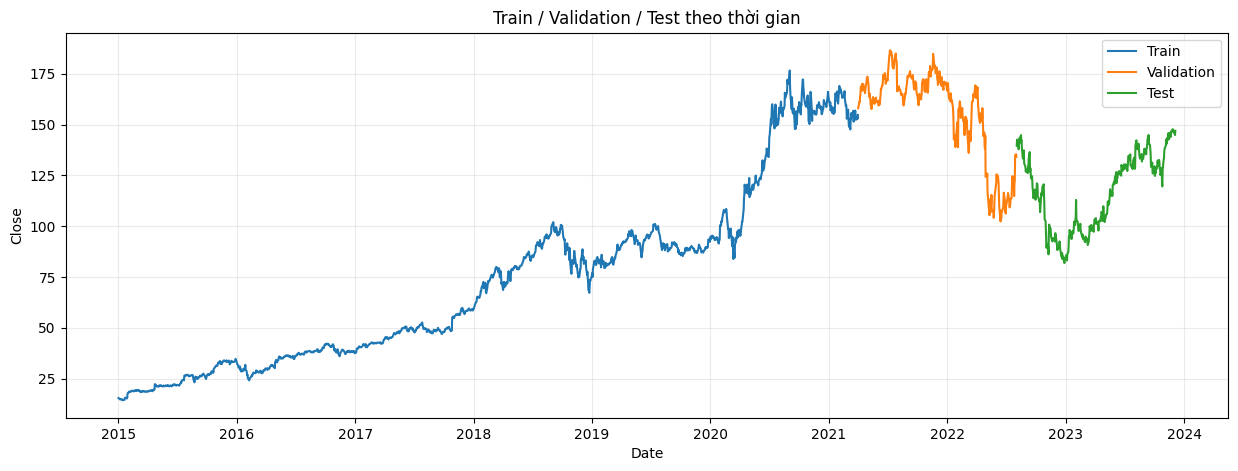

In [14]:
plt.figure(figsize=(15, 5))
plt.plot(train_df["Date"], train_df["Close"], label="Train")
plt.plot(val_df["Date"], val_df["Close"], label="Validation")
plt.plot(test_df["Date"], test_df["Close"], label="Test")

plt.title("Train / Validation / Test theo thời gian")
plt.xlabel("Date")
plt.ylabel("Close")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 7. Scaling

In [15]:
# Chỉ FIT scaler trên Train để tránh Data Leakage.

scaler = MinMaxScaler(feature_range=(0, 1))

scaler.fit(train_df[["Close"]])

train_scaled = scaler.transform(train_df[["Close"]]).reshape(-1)
val_scaled = scaler.transform(val_df[["Close"]]).reshape(-1)
test_scaled = scaler.transform(test_df[["Close"]]).reshape(-1)

# Transform toàn bộ modeling period bằng scaler đã fit từ Train.
all_scaled = scaler.transform(model_df[["Close"]]).reshape(-1)

print("Train scaled range:",
      round(train_scaled.min(), 4), "->", round(train_scaled.max(), 4))

print("Validation scaled range:",
      round(val_scaled.min(), 4), "->", round(val_scaled.max(), 4))

print("Test scaled range:",
      round(test_scaled.min(), 4), "->", round(test_scaled.max(), 4))

Train scaled range: 0.0 -> 1.0
Validation scaled range: 0.5422 -> 1.0616
Test scaled range: 0.4159 -> 0.8222


`MinMaxScaler` chỉ **học min/max từ Train**.  
Validation và Test chỉ dùng `.transform()`.

Nếu Validation/Test hơi vượt ngoài `[0, 1]` thì không phải lỗi; điều đó chỉ có nghĩa tương lai có giá nằm ngoài phạm vi Train.

## 8. Create Sequences

Ta dùng **30 phiên trước** để dự đoán phiên tiếp theo.

Ví dụ:

```text
Ngày 1 ... Ngày 30  →  Close ngày 31
Ngày 2 ... Ngày 31  →  Close ngày 32
...
```

Đầu vào RNN có dạng:

```text
(samples, timesteps, features)
```

Ở đây:

- `timesteps = 30`
- `features = 1` (`Close`)

In [16]:
SEQ_LENGTH = 30

def create_sequences_by_target_range(
    values,
    seq_length,
    target_start,
    target_end
):
    X, y = [], []

    start = max(seq_length, target_start)

    for target_idx in range(start, target_end):
        X.append(
            values[target_idx - seq_length:target_idx]
        )
        y.append(
            values[target_idx]
        )

    X = np.asarray(X, dtype=np.float32)
    y = np.asarray(y, dtype=np.float32)

    # (samples, timesteps, features)
    X = X.reshape(X.shape[0], X.shape[1], 1)

    return X, y


X_train, y_train = create_sequences_by_target_range(
    all_scaled,
    SEQ_LENGTH,
    SEQ_LENGTH,
    train_end
)

X_val, y_val = create_sequences_by_target_range(
    all_scaled,
    SEQ_LENGTH,
    train_end,
    val_end
)

X_test, y_test = create_sequences_by_target_range(
    all_scaled,
    SEQ_LENGTH,
    val_end,
    n
)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nX_val:", X_val.shape)
print("y_val:", y_val.shape)

print("\nX_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (1542, 30, 1)
y_train: (1542,)

X_val: (337, 30, 1)
y_val: (337,)

X_test: (338, 30, 1)
y_test: (338,)


In [17]:
print("Một sample có shape:", X_train[0].shape)
print("30 Close đã scale:")
print(X_train[0].reshape(-1))

print("\nTarget:")
print(y_train[0])

Một sample có shape: (30, 1)
30 Close đã scale:
[0.00664817 0.00469718 0.0025705  0.00353521 0.00416397 0.00307597
 0.00137463 0.00240099 0.00194791 0.         0.00116813 0.00076745
 0.0031746  0.00720296 0.00784096 0.00699954 0.00610264 0.00522731
 0.00765295 0.0208291  0.02389274 0.02360919 0.02397904 0.02679612
 0.02691633 0.02576976 0.02652181 0.02718139 0.02780706 0.02924333]

Target:
0.027270766


## 9. Build RNN

In [18]:
def build_rnn(units=50, learning_rate=0.001):
    tf.keras.utils.set_random_seed(SEED)
    network = Sequential([
        Input(shape=(SEQ_LENGTH, 1)),
        SimpleRNN(units, activation="tanh"),
        Dense(1)
    ], name="StockSimpleRNN")
    network.compile(optimizer=Adam(learning_rate=learning_rate, clipnorm=1.0),
                    loss="mse", metrics=["mae"])
    return network

tf.keras.backend.clear_session()
model = build_rnn()
model.summary()

Model: "StockSimpleRNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)               │ (None, 50)                  │           2,600 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1)                   │              51 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,651 (10.36 KB)

 Trainable params: 2,651 (10.36 KB)

 Non-trainable params: 0 (0.00 B)

### Kiến trúc SimpleRNN thuần

```text
30 giá Close đã scale → SimpleRNN(tanh) → Dense/Linear(1) → Close dự đoán
```

Toàn bộ dự đoán được tạo bởi RNN và lớp đầu ra đã huấn luyện.
Không có đường cộng trực tiếp giá phiên trước vào đầu ra.
Chỉ chọn checkpoint sau một epoch huấn luyện trở lên bằng validation MSE.
Persistence (`giá ngày mai = giá hôm nay`) được tính riêng khi đánh giá.
Ba cấu hình thử nghiệm được xác định trước khi xem kết quả Test.

## 10. Compile

In [19]:
print("Compiled in build_rnn: Adam + gradient clipping, MSE loss.")

Compiled in build_rnn: Adam + gradient clipping, MSE loss.


## 11. Train

In [20]:
RUN_TUNING = os.environ.get("RNN_TUNE", "1") == "1"
tuning_rows = []
best_val_mse = float("inf")
candidates = [(32, 0.001), (50, 0.001), (50, 0.0005)] if RUN_TUNING else [(50, 0.001)]
for units, learning_rate in candidates:
    candidate = build_rnn(units, learning_rate)
    candidate_history = candidate.fit(
        X_train, y_train, validation_data=(X_val, y_val), epochs=80,
        batch_size=32, shuffle=True,
        callbacks=[EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
                   ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-5)],
        verbose=0)
    score = float(np.mean((candidate.predict(X_val, verbose=0).ravel() - y_val) ** 2))
    best_epoch = int(np.argmin(candidate_history.history["val_loss"])) + 1
    tuning_rows.append(dict(units=units, learning_rate=learning_rate, val_mse=score, best_epoch=best_epoch,
                            epochs=len(candidate_history.history["loss"])))
    print(tuning_rows[-1])
    if not np.isfinite(score):
        raise RuntimeError("Non-finite validation MSE")
    if score < best_val_mse:
        best_val_mse = score
        model, history = candidate, candidate_history
        selected_config = dict(hidden_size=units, learning_rate=learning_rate, best_epoch=best_epoch)
tuning_df = pd.DataFrame(tuning_rows).sort_values("val_mse")
display(tuning_df)
print("Selected using validation only:", selected_config)

{'units': 32, 'learning_rate': 0.001, 'val_mse': 0.0007671655621379614, 'best_epoch': 22, 'epochs': 30}
{'units': 50, 'learning_rate': 0.001, 'val_mse': 0.0007013718131929636, 'best_epoch': 80, 'epochs': 80}
{'units': 50, 'learning_rate': 0.0005, 'val_mse': 0.0010301147121936083, 'best_epoch': 80, 'epochs': 80}


,units,learning_rate,val_mse,best_epoch,epochs
1,50,0.0010,0.000701,80,80
0,32,0.0010,0.000767,22,30
2,50,0.0005,0.001030,80,80


Selected using validation only: {'hidden_size': 50, 'learning_rate': 0.001, 'best_epoch': 80}


## 12. Plot Training / Validation Loss

In [21]:
history_df = pd.DataFrame(history.history)

print("Số epoch đã chạy:", len(history_df))
display(history_df.tail())

Số epoch đã chạy: 80


,loss,mae,val_loss,val_mae,learning_rate
75,0.000135,0.007269,0.000703,0.020111,0.00001
76,0.000135,0.007267,0.000702,0.020107,0.00001
77,0.000135,0.007265,0.000702,0.020102,0.00001
78,0.000135,0.007263,0.000702,0.020098,0.00001
79,0.000135,0.007261,0.000701,0.020093,0.00001


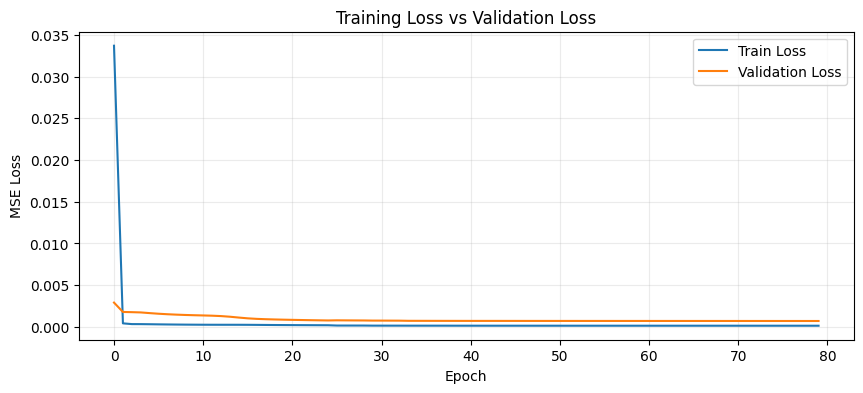

In [22]:
plt.figure(figsize=(10, 4))

plt.plot(
    history_df["loss"],
    label="Train Loss"
)

plt.plot(
    history_df["val_loss"],
    label="Validation Loss"
)

plt.title("Training Loss vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

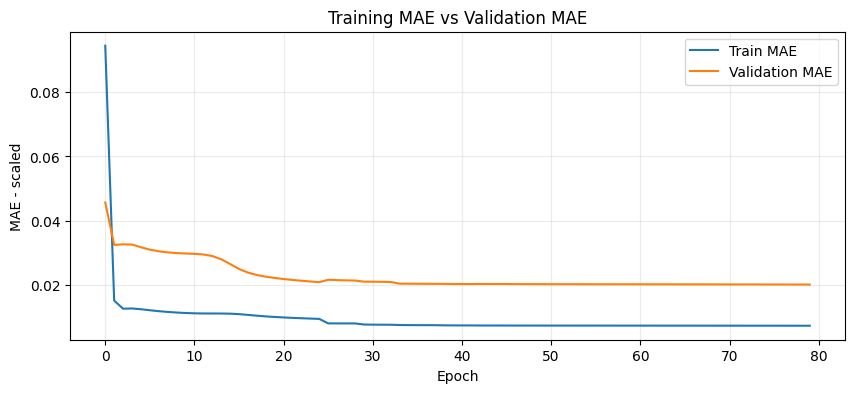

In [23]:
plt.figure(figsize=(10, 4))

plt.plot(
    history_df["mae"],
    label="Train MAE"
)

plt.plot(
    history_df["val_mae"],
    label="Validation MAE"
)

plt.title("Training MAE vs Validation MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE - scaled")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 13. Predict

In [24]:
y_pred_scaled = (
    model.predict(X_test, verbose=0)
    .reshape(-1)
)

print("Số dự đoán:", len(y_pred_scaled))
print("5 dự đoán đầu - scaled:")
print(y_pred_scaled[:5])

Số dự đoán: 338
5 dự đoán đầu - scaled:
[0.73514    0.7516152  0.77627045 0.7812048  0.78109145]


## 14. Inverse Transform

In [25]:
y_test_actual = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).reshape(-1)

y_pred_actual = scaler.inverse_transform(
    y_pred_scaled.reshape(-1, 1)
).reshape(-1)

print("5 giá trị thật:")
print(y_test_actual[:5])

print("\n5 giá trị RNN dự đoán:")
print(y_pred_actual[:5])

5 giá trị thật:
[139.52 142.57 140.8  139.41 137.83]

5 giá trị RNN dự đoán:
[133.60559 136.27827 140.27797 141.07845 141.06006]


## 15. Evaluate + Naive Baseline

Ngoài MAE/MSE/RMSE của RNN, ta thêm một **Naive Baseline**:

> Giá ngày mai ≈ giá đóng cửa hôm nay.

Đây là baseline rất tự nhiên với dữ liệu chứng khoán.  
Mục đích là để biết RNN có thực sự học được gì hơn một dự đoán cực kỳ đơn giản hay không.

In [26]:
# Date tương ứng với các target thuộc Test
test_dates = (
    model_df["Date"]
    .iloc[val_end: val_end + len(y_test_actual)]
    .reset_index(drop=True)
)

# Close của phiên ngay trước target
prev_close = (
    model_df["Close"]
    .iloc[val_end - 1: val_end - 1 + len(y_test_actual)]
    .to_numpy()
)

baseline_pred = prev_close.copy()

# RNN metrics
rnn_mae = mean_absolute_error(
    y_test_actual,
    y_pred_actual
)

rnn_mse = mean_squared_error(
    y_test_actual,
    y_pred_actual
)

rnn_rmse = np.sqrt(rnn_mse)

# Baseline metrics
baseline_mae = mean_absolute_error(
    y_test_actual,
    baseline_pred
)

baseline_mse = mean_squared_error(
    y_test_actual,
    baseline_pred
)

baseline_rmse = np.sqrt(baseline_mse)

metrics_df = pd.DataFrame({
    "Model": ["SimpleRNN", "Naive baseline"],
    "MAE": [rnn_mae, baseline_mae],
    "MSE": [rnn_mse, baseline_mse],
    "RMSE": [rnn_rmse, baseline_rmse]
})

display(metrics_df)

,Model,MAE,MSE,RMSE
0,SimpleRNN,2.431536,10.161628,3.187731
1,Naive baseline,2.030296,7.292410,2.700446


In [27]:
# Direction Accuracy:
# dự đoán đúng hướng tăng/giảm so với phiên trước hay không.


actual_change = y_test_actual.astype(np.float64) - prev_close
predicted_change = y_pred_actual.astype(np.float64) - prev_close
actual_direction = np.sign(np.where(np.abs(actual_change) <= 1e-4, 0.0, actual_change))
pred_direction = np.sign(np.where(np.abs(predicted_change) <= 1e-4, 0.0, predicted_change))
direction_accuracy = np.mean(
    actual_direction == pred_direction
)

print(
    f"RNN Direction Accuracy: "
    f"{direction_accuracy * 100:.2f}%"
)

print()

if np.isclose(rnn_rmse, baseline_rmse, rtol=0, atol=1e-4):
    print("RNN and persistence have equivalent RMSE within numerical tolerance.")
elif rnn_rmse < baseline_rmse:
    improvement = (
        (baseline_rmse - rnn_rmse)
        / baseline_rmse
        * 100
    )

    print(
        f"SimpleRNN có RMSE thấp hơn baseline "
        f"khoảng {improvement:.2f}%."
    )
else:
    gap = (
        (rnn_rmse - baseline_rmse)
        / baseline_rmse
        * 100
    )

    print(
        f"SimpleRNN có RMSE cao hơn baseline "
        f"khoảng {gap:.2f}%."
    )

    print(
        "Điều này không phải lỗi code. "
        "Dự đoán giá cổ phiếu ngày kế tiếp là bài toán khó; "
        "SimpleRNN cơ bản chưa chắc vượt được persistence baseline."
    )

direction_table = pd.DataFrame({
    "Direction": ["Down", "Flat", "Up"],
    "Actual_count": [(actual_direction == v).sum() for v in [-1, 0, 1]],
    "Predicted_count": [(pred_direction == v).sum() for v in [-1, 0, 1]]
})
display(direction_table)

RNN Direction Accuracy: 53.25%

SimpleRNN có RMSE cao hơn baseline khoảng 18.04%.
Điều này không phải lỗi code. Dự đoán giá cổ phiếu ngày kế tiếp là bài toán khó; SimpleRNN cơ bản chưa chắc vượt được persistence baseline.


,Direction,Actual_count,Predicted_count
0,Down,165,127
1,Flat,2,0
2,Up,171,211


## 16. Actual vs Predicted

In [28]:
result_df = pd.DataFrame({
    "Date": test_dates,
    "Previous_Close": prev_close,
    "Actual_Close": y_test_actual,
    "RNN_Predicted_Close": y_pred_actual,
    "Baseline_Predicted_Close": baseline_pred
})

result_df["RNN_Absolute_Error"] = np.abs(
    result_df["Actual_Close"]
    - result_df["RNN_Predicted_Close"]
)

display(result_df.head(10))

,Date,Previous_Close,Actual_Close,RNN_Predicted_Close,Baseline_Predicted_Close,RNN_Absolute_Error
0,2022-08-03,134.160004,139.520004,133.605591,134.160004,5.914413
1,2022-08-04,139.520004,142.570007,136.278275,139.520004,6.291733
2,2022-08-05,142.570007,140.800003,140.277969,142.570007,0.522034
3,2022-08-08,140.800003,139.410004,141.078445,140.800003,1.668442
4,2022-08-09,139.410004,137.830002,141.060059,139.410004,3.230057
5,2022-08-10,137.830002,142.690002,141.269272,137.830002,1.420731
6,2022-08-11,142.690002,140.639999,141.981461,142.690002,1.341461
7,2022-08-12,140.639999,143.550003,139.179077,140.639999,4.370926
8,2022-08-15,143.550003,143.179993,142.228439,143.550003,0.951553
9,2022-08-16,143.179993,144.779999,142.911880,143.179993,1.868118


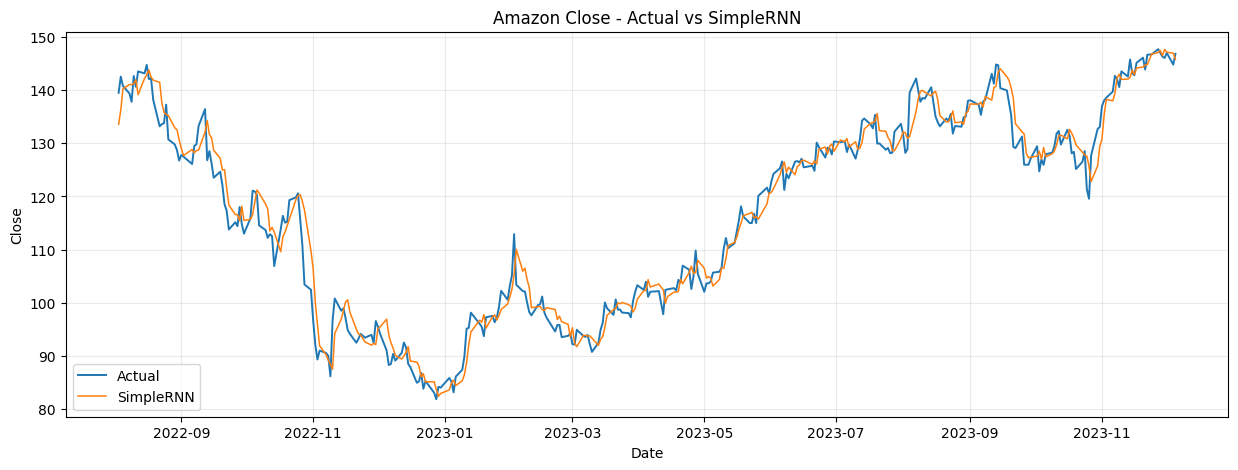

In [29]:
# Vẽ toàn bộ Test

plt.figure(figsize=(15, 5))

plt.plot(
    result_df["Date"],
    result_df["Actual_Close"],
    label="Actual",
    linewidth=1.4
)

plt.plot(
    result_df["Date"],
    result_df["RNN_Predicted_Close"],
    label="SimpleRNN",
    linewidth=1.1
)

plt.title("Amazon Close - Actual vs SimpleRNN")
plt.xlabel("Date")
plt.ylabel("Close")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

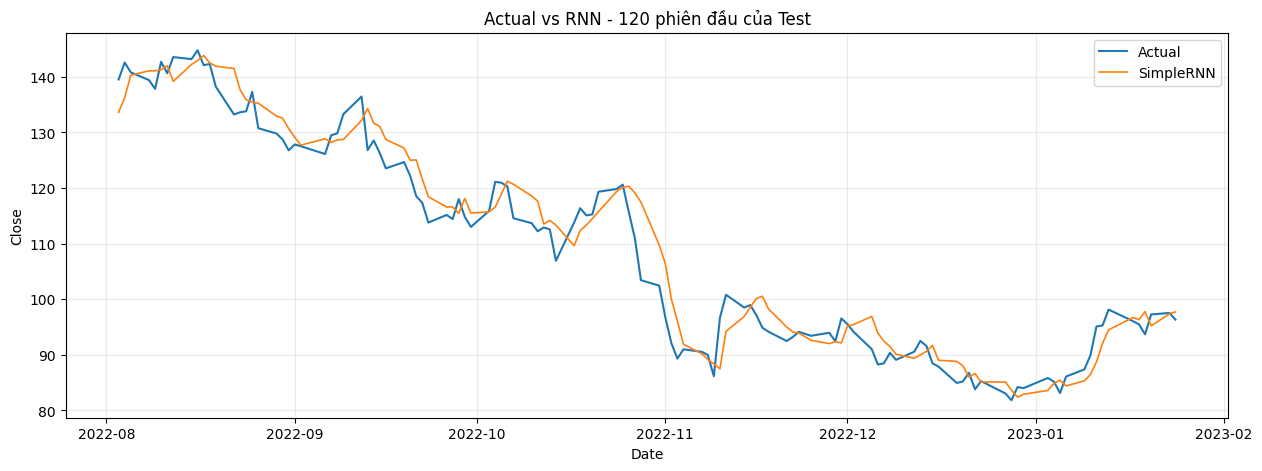

In [30]:
# Zoom 120 phiên đầu của Test để dễ demo

N_PLOT = min(120, len(result_df))

plt.figure(figsize=(15, 5))

plt.plot(
    result_df["Date"].iloc[:N_PLOT],
    result_df["Actual_Close"].iloc[:N_PLOT],
    label="Actual",
    linewidth=1.5
)

plt.plot(
    result_df["Date"].iloc[:N_PLOT],
    result_df["RNN_Predicted_Close"].iloc[:N_PLOT],
    label="SimpleRNN",
    linewidth=1.2
)

plt.title(
    f"Actual vs RNN - {N_PLOT} phiên đầu của Test"
)

plt.xlabel("Date")
plt.ylabel("Close")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

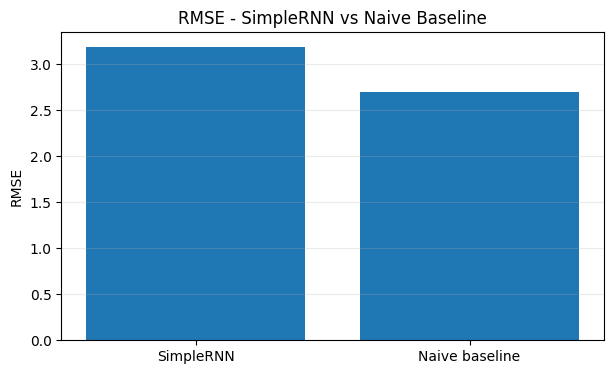

In [31]:
# So sánh RMSE trực quan

plt.figure(figsize=(7, 4))

plt.bar(
    metrics_df["Model"],
    metrics_df["RMSE"]
)

plt.title("RMSE - SimpleRNN vs Naive Baseline")
plt.ylabel("RMSE")
plt.grid(axis="y", alpha=0.25)
plt.show()

## 17. Lưu kết quả và Model

In [32]:
import hashlib
import importlib.metadata

def save_metadata(path, *, task, framework, seed, seq_length, dataset, **extra):
    digest = hashlib.sha256()
    with Path(dataset).open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)
    versions = {}
    for name in ("numpy", "pandas", "scikit-learn", "tensorflow", "keras", "torch"):
        try:
            versions[name] = importlib.metadata.version(name)
        except importlib.metadata.PackageNotFoundError:
            pass
    metadata = dict(schema_version=1, task=task, framework=framework, seed=seed,
                    seq_length=seq_length, dataset_sha256=digest.hexdigest(),
                    package_versions=versions, **extra)
    Path(path).write_text(json.dumps(metadata, indent=2, ensure_ascii=False, allow_nan=False), encoding="utf-8")
    return metadata

prediction_path = (
    RESULTS_DIR
    / "AMZN_Keras_predictions.csv"
)

result_df.to_csv(
    prediction_path,
    index=False
)

model_path = (
    RESULTS_DIR
    / "AMZN_Keras_SimpleRNN.keras"
)

model.save(model_path)

print("Đã lưu predictions:")
print(prediction_path)

print("\nĐã lưu model:")
print(model_path)
metadata_extra = dict(**selected_config, selection_metric='val_mse',
    train_samples=len(X_train), validation_samples=len(X_val), test_samples=len(X_test))

metadata_extra.update(architecture="simple_rnn", scaler={
    "scale": scaler.scale_.tolist(), "min": scaler.min_.tolist(),
    "data_min": scaler.data_min_.tolist(), "data_max": scaler.data_max_.tolist()},
    split_dates={"train_end": str(train_df.Date.max()), "val_start": str(val_df.Date.min()),
                 "val_end": str(val_df.Date.max()), "test_start": str(test_df.Date.min())},
    test_metrics={"mae": float(rnn_mae), "rmse": float(rnn_rmse),
                  "baseline_rmse": float(baseline_rmse), "direction_accuracy": float(direction_accuracy)})
tuning_df.to_csv(RESULTS_DIR / "AMZN_Keras_validation_search.csv", index=False)
metrics_df.to_csv(RESULTS_DIR / "AMZN_Keras_metrics.csv", index=False)

metadata_extra["selected_val_mse"] = float(best_val_mse)
metadata_extra["trained_checkpoint_only"] = True

save_metadata(model_path.with_suffix(".json"), task="stock", framework="keras",
              seed=SEED, seq_length=SEQ_LENGTH, dataset=DATA_PATH, **metadata_extra)
history_df.to_csv(RESULTS_DIR / "AMZN_Keras_history.csv", index=False)

Đã lưu predictions:
D:\A06\results\AMZN_Keras_predictions.csv

Đã lưu model:
D:\A06\results\AMZN_Keras_SimpleRNN.keras


## 18. Kết quả lựa chọn cấu hình trên Validation

Các cấu hình đã được thử trước bước Predict trên Test. Test chỉ dùng để báo cáo cuối cùng.

In [33]:
display(tuning_df)

,units,learning_rate,val_mse,best_epoch,epochs
1,50,0.0010,0.000701,80,80
0,32,0.0010,0.000767,22,30
2,50,0.0005,0.001030,80,80


## 19. Kết luận

In [34]:
print("===== KẾT QUẢ CUỐI =====")
print(
    f"Modeling period : "
    f"{model_df['Date'].min().date()} "
    f"-> {model_df['Date'].max().date()}"
)

print(
    f"Sequence length : "
    f"{SEQ_LENGTH} phiên"
)

print(
    f"Train samples   : "
    f"{len(X_train):,}"
)

print(
    f"Validation      : "
    f"{len(X_val):,}"
)

print(
    f"Test samples    : "
    f"{len(X_test):,}"
)

print()
print(
    f"RNN MAE         : "
    f"{rnn_mae:.4f}"
)

print(
    f"RNN MSE         : "
    f"{rnn_mse:.4f}"
)

print(
    f"RNN RMSE        : "
    f"{rnn_rmse:.4f}"
)

print(
    f"Direction Acc.  : "
    f"{direction_accuracy * 100:.2f}%"
)

print()
print(
    f"Baseline RMSE   : "
    f"{baseline_rmse:.4f}"
)

===== KẾT QUẢ CUỐI =====
Modeling period : 2015-01-02 -> 2023-12-05
Sequence length : 30 phiên
Train samples   : 1,542
Validation      : 337
Test samples    : 338

RNN MAE         : 2.4315
RNN MSE         : 10.1616
RNN RMSE        : 3.1877
Direction Acc.  : 53.25%

Baseline RMSE   : 2.7004


### Cách diễn giải kết quả

- Đây là dự đoán một phiên tiếp theo, dùng 30 giá lịch sử thực đã biết.
- Model chính là SimpleRNN thuần đã train, chọn bằng Validation MSE.
- Baseline persistence là đối chứng độc lập, không thay thế đầu ra RNN.
- Nếu RNN có RMSE cao hơn baseline: chưa có bằng chứng RNN tạo ra lợi ích
  dự báo vượt persistence trên tập Test này. Không kết luận model đã học
  được xu hướng chỉ vì hai đường trên biểu đồ trông gần nhau.
- Direction Accuracy cần đọc cùng tỷ lệ dự đoán tăng/giảm/không đổi.
- Đây là một seed và một holdout; LSTM/GRU, thêm OHLCV hoặc nhiều seed
  là các thí nghiệm tiếp theo, chưa phải cải thiện đã được chứng minh.

In [35]:
# Tải lại trực tiếp bằng framework và JSON; không cần file Python ngoài.
saved_metadata = json.loads(model_path.with_suffix(".json").read_text(encoding="utf-8"))
loaded_model = tf.keras.models.load_model(model_path, compile=False, safe_mode=True)

def predict_saved_closes(windows):
    raw = np.asarray(windows, dtype=np.float64)
    if raw.ndim == 1:
        raw = raw[None, :]
    if raw.ndim != 2 or raw.shape[1] != saved_metadata["seq_length"] or not np.isfinite(raw).all():
        raise ValueError("Expected finite closing-price windows with the saved sequence length")
    scale = saved_metadata["scaler"]["scale"][0]
    offset = saved_metadata["scaler"]["min"][0]
    values = (raw * scale + offset).astype(np.float32)[..., None]
    scaled = loaded_model(values, training=False).numpy().reshape(-1)

    return (scaled - offset) / scale

raw_windows = np.stack([model_df.Close.to_numpy()[i-SEQ_LENGTH:i] for i in range(val_end, n)])
np.testing.assert_allclose(predict_saved_closes(raw_windows), y_pred_actual, rtol=1e-5, atol=1e-4)
print("PASS: reloaded model + scaler reproduce all test predictions.")

PASS: reloaded model + scaler reproduce all test predictions.
